Predicting Trajectories: LSTM Model
==============

This notebook contains only the model definition and training. Data preprocessing and DataSet creation are sourced out to create_datasets.

***1. Imports***

In [1]:
# Core data processing
import pandas as pd
import numpy as np
from pathlib import Path
import sys

# Machine Learning
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.model_selection import train_test_split

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Utilities
import warnings
warnings.filterwarnings('ignore')

# Create datasets module
sys.path.append("../src")
from create_datasets import create_datasets, denormalize_xy, to_latlon

print("All imports completed successfully!")

All imports completed successfully!


***2. Creating Datasets and -Loaders***

In [2]:
WORKS_ON_FULL_DATA = True

# Create datasets for a specific ship type
train_dataset, val_dataset, test_dataset = create_datasets(input_files='../data/processed', ship_type='Cargo', with_full_data=WORKS_ON_FULL_DATA)

print(f"Train dataset: {len(train_dataset)} sequences")
print(f"Val dataset: {len(val_dataset)} sequences") 
print(f"Test dataset: {len(test_dataset)} sequences")

# Create data loaders
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"\nDataLoaders created with batch_size={batch_size}")
print(f"Train batches: {len(train_loader)}")
print(f"Val batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

# Test one batch
sample_input, sample_target = next(iter(train_loader))
print(f"\nSample batch - Input shape: {sample_input.shape}, Target shape: {sample_target.shape}")

Discovered 3073 parquet files from 373 vessels.


Total loaded trajectories: 3073


Total resampled trajectories: 3059


Train dataset: 1304830 sequences
Val dataset: 274720 sequences
Test dataset: 275170 sequences

DataLoaders created with batch_size=64
Train batches: 20388
Val batches: 4293
Test batches: 4300

Sample batch - Input shape: torch.Size([64, 29, 7]), Target shape: torch.Size([64, 2])


***3. LSTM Model Architecture***

In [3]:
# Some model hyperparameters
HIDDEN_SIZE = 128
NUM_LAYERS = 2
DROPOUT = 0.1

In [4]:
class LSTMPredictor(nn.Module):
    def __init__(self, input_size=7, hidden_size=128, num_layers=2, output_size=2, dropout=0.1):
        """
        Simplified LSTM model to reduce overfitting
        """
        super(LSTMPredictor, self).__init__()
        
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        # Smaller LSTM layer
        self.lstm = nn.LSTM(input_size, 
                            hidden_size, 
                            num_layers, 
                            batch_first=True, 
                            dropout=dropout if num_layers > 1 else 0.0,)
        
        # Single output layer
        self.fc = nn.Linear(hidden_size, output_size)
        
        # Add dropout for regularization
        self.dropout = nn.Dropout(dropout)
            
    def forward(self, x, hidden=None):
        # LSTM forward pass
        lstm_out, hidden = self.lstm(x, hidden)
        
        # Apply dropout
        lstm_out = self.dropout(lstm_out)

        # Use only the last output for prediction
        last_hidden = lstm_out[:, -1, :]  #(batch, hidden_size)
        
        # Output layer
        output = self.fc(last_hidden)
        
        return output, hidden

# Create model instance
print("=== CREATING LSTM MODEL ===")

# Determine input size from sample data
sample_input, sample_target = next(iter(train_loader))
input_size = sample_input.shape[-1]  # Should be 4 (Lat, Lon, SOG, COG)
output_size = sample_target.shape[-1]  # Should be 2 (Lat, Lon)

model = LSTMPredictor(
    input_size=input_size,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    output_size=output_size,
    dropout=DROPOUT
)

print(f"Model created with:")
print(f"  Input size: {input_size}")
print(f"  Hidden size: {HIDDEN_SIZE}")
print(f"  Layers: {NUM_LAYERS}")
print(f"  Output size: {output_size}")

# Test model with sample input
print("sample_input dtype:", sample_input.dtype)
with torch.no_grad():
    sample_output, _ = model(sample_input)
    print(f"Sample input shape: {sample_input.shape}")
    print(f"Sample output shape: {sample_output.shape}")

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

=== CREATING LSTM MODEL ===
Model created with:
  Input size: 7
  Hidden size: 128
  Layers: 2
  Output size: 2
sample_input dtype: torch.float32
Sample input shape: torch.Size([64, 29, 7])
Sample output shape: torch.Size([64, 2])

Total parameters: 202,498
Trainable parameters: 202,498


***4. Training Setup***

In [5]:
# Setup loss function and optimizer
print("=== TRAINING SETUP ===")

# Mean Squared Error loss for regression
criterion = nn.MSELoss()

# Adam optimizer with learning rate
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

# Training parameters
num_epochs = 50
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Move model to device
model = model.to(device)
print(f"Model moved to: {device}")

print(f"\nTraining configuration:")
print(f"Loss function: MSE Loss")
print(f"Optimizer: Adam (lr=0.001)")
print(f"Scheduler: ReduceLROnPlateau")
print(f"Epochs: {num_epochs}")
print(f"Device: {device}")

=== TRAINING SETUP ===


Model moved to: cpu

Training configuration:
Loss function: MSE Loss
Optimizer: Adam (lr=0.001)
Scheduler: ReduceLROnPlateau
Epochs: 50
Device: cpu


***5. Utilities to Store/Load Model parameters***

In [6]:
# Save the trained model
def save_model_and_training_state(model, optimizer, train_losses, val_losses, filepath):
    """
    Save model weights, optimizer state, and training history
    """
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_losses': train_losses,
        'val_losses': val_losses,
        'epoch': len(train_losses)
    }, filepath)
    print(f"Model saved to {filepath}")



# Load the saved model
def load_model_and_training_state(filepath):
    """
    Load model weights, optimizer state, and training history
    """
    checkpoint = torch.load(filepath)
    
    model = LSTMPredictor(input_size=input_size, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, output_size=output_size)
    model.load_state_dict(checkpoint['model_state_dict'])
    
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    
    return model, optimizer, checkpoint['train_losses'], checkpoint['val_losses'], checkpoint['epoch']


***6. Training Loop***

In [7]:
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs):
    """
    Training loop with validation
    """
    print("=== STARTING TRAINING ===")
    
    train_losses = []
    val_losses = []
    
    for epoch in range(num_epochs):
        # Training phase
        model.train()
        train_loss = 0.0
        
        for batch_idx, (inputs, targets) in enumerate(train_loader):
            inputs, targets = inputs.to(device), targets.to(device)
            
            # Zero gradients
            optimizer.zero_grad()
            
            # Forward pass
            outputs, _ = model(inputs)
            loss = criterion(outputs, targets)
            
            # Backward pass
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
        
        # Validation phase
        model.eval()
        val_loss = 0.0
        
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs, _ = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item()
        
        # Average losses
        train_loss /= len(train_loader)
        val_loss /= len(val_loader)
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        
        # Update learning rate
        scheduler.step(val_loss)
        
        # Print progress
        if (epoch + 1) % 5 == 0:
            current_lr = optimizer.param_groups[0]['lr']
            print(f'Epoch [{epoch+1:02d}/{num_epochs}] | '
                  f'Train Loss: {train_loss:.6f} | '
                  f'Val Loss: {val_loss:.6f} | '
                  f'LR: {current_lr:.6f}')
    
    print("Training completed!")

    # Save after training
    save_model_and_training_state(model, optimizer, train_losses, val_losses, filepath='lstm_model.pth')

    print("Parameters saved after training.\n")

    return train_losses, val_losses

# Start training
train_losses, val_losses = train_model(
    model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs
)

=== STARTING TRAINING ===


Epoch [05/50] | Train Loss: 0.001971 | Val Loss: 0.000243 | LR: 0.001000


Epoch [10/50] | Train Loss: 0.001884 | Val Loss: 0.000180 | LR: 0.001000


Epoch [15/50] | Train Loss: 0.001848 | Val Loss: 0.000147 | LR: 0.001000


Epoch [20/50] | Train Loss: 0.001782 | Val Loss: 0.000112 | LR: 0.000500


Epoch [25/50] | Train Loss: 0.001778 | Val Loss: 0.000139 | LR: 0.000500


Epoch [30/50] | Train Loss: 0.001771 | Val Loss: 0.000102 | LR: 0.000500


Epoch [35/50] | Train Loss: 0.001765 | Val Loss: 0.000100 | LR: 0.000500


Epoch [40/50] | Train Loss: 0.001769 | Val Loss: 0.000144 | LR: 0.000500


Epoch [45/50] | Train Loss: 0.001736 | Val Loss: 0.000082 | LR: 0.000250


Epoch [50/50] | Train Loss: 0.001734 | Val Loss: 0.000068 | LR: 0.000250
Training completed!
Model saved to lstm_model.pth
Parameters saved after training.



***7. Visualization*** 
(Leftover from old implementation)

=== VISUALIZING RESULTS ===


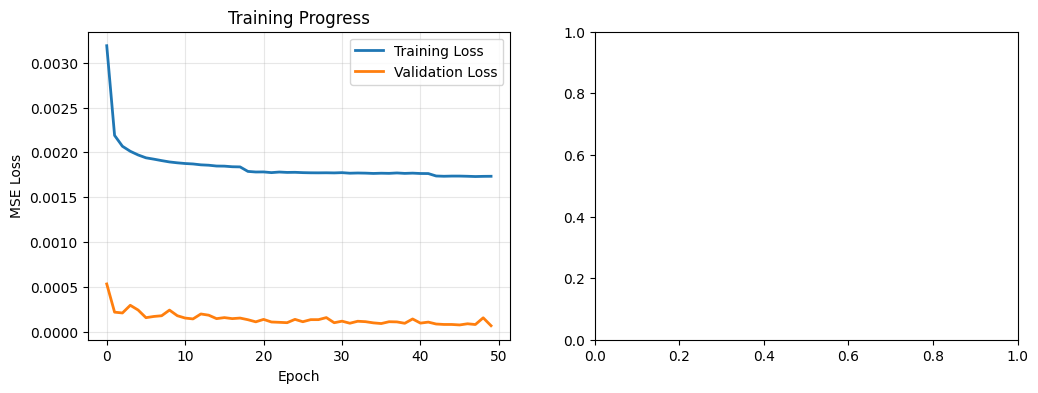

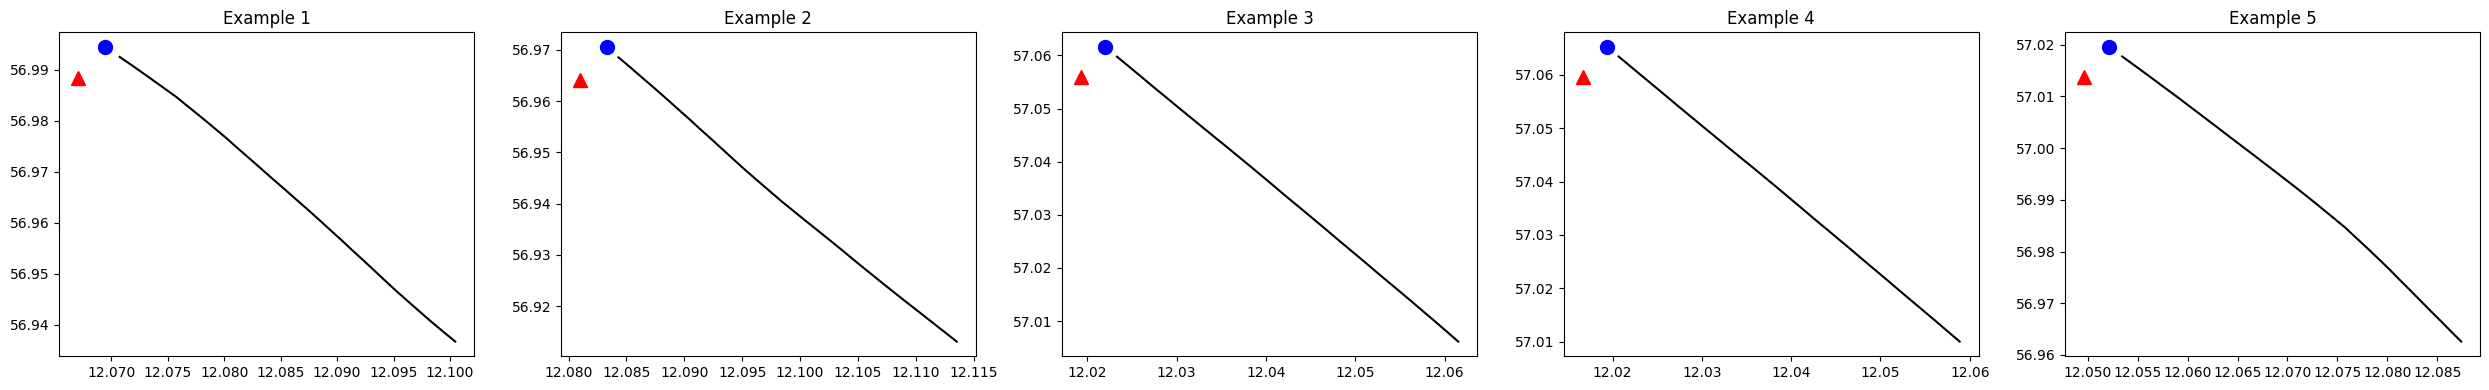


Final Metrics:
Training Loss: 0.001734
Validation Loss: 0.000068


Test Loss: 0.000042


In [8]:
def visualize_results(filepath, test_loader):
    """
    Create visualization plots for training results and predictions
    """
    print("=== VISUALIZING RESULTS ===")

    # load model from file
    model, _, train_losses, val_losses, _ = load_model_and_training_state(filepath)
    
    # Plot 1: Training and validation loss
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Training Loss', linewidth=2)
    plt.plot(val_losses, label='Validation Loss', linewidth=2)
    plt.xlabel('Epoch')
    plt.ylabel('MSE Loss')
    plt.title('Training Progress')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Plot 2: Sample predictions vs actual
    plt.subplot(1, 2, 2)
    
    # Get a random batch from *test_loader*
    model.eval()
    with torch.no_grad():
        test_inputs, test_targets = next(iter(test_loader))
        test_inputs, test_targets = test_inputs.to(device), test_targets.to(device)

        # Choose a random sequence index inside the batch
        batch_size = test_inputs.shape[0]
        seq_idx = np.random.randint(0, batch_size)

        # Predict
        test_outputs, _ = model(test_inputs)

        num_examples = 5
        fig, axes = plt.subplots(1, num_examples, figsize=(5*num_examples, 4))

        for k in range(num_examples):
            seq_idx = np.random.randint(0, batch_size)
            ax = axes[k]

            trajectory = test_inputs[seq_idx].cpu().numpy()[:, :2]
            actual = test_targets[seq_idx].cpu().numpy()
            predicted = test_outputs[seq_idx].cpu().numpy()

            # denormalize 
            trajectory = denormalize_xy(trajectory)
            actual = denormalize_xy(actual)[0]
            predicted = denormalize_xy(predicted)[0]

            # also convert back to lat/lon
            trajectory = to_latlon(trajectory)
            actual = to_latlon(actual)[0]
            predicted = to_latlon(predicted)[0]

            # plot trajectory as line
            ax.plot(trajectory[:,0], trajectory[:,1], "k-", label="Input Trajectory")
            # plot actual and predicted as thick points
            ax.plot(actual[0], actual[1], "bo", markersize=10, label="Actual")
            ax.plot(predicted[0], predicted[1], "r^", markersize=10, label="Predicted")
            ax.set_title(f"Example {k+1}")

        plt.tight_layout()
        plt.show()
    
    # Print final metrics
    final_train_loss = train_losses[-1]
    final_val_loss = val_losses[-1]
    print(f"\nFinal Metrics:")
    print(f"Training Loss: {final_train_loss:.6f}")
    print(f"Validation Loss: {final_val_loss:.6f}")
    
    # Calculate test loss
    test_loss = 0.0
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs, _ = model(inputs)
            loss = criterion(outputs, targets)
            test_loss += loss.item()
    
    test_loss /= len(test_loader)
    print(f"Test Loss: {test_loss:.6f}")

# Generate visualizations with denormalization
path_to_model = 'lstm_model.pth'
visualize_results(path_to_model, test_loader)

***8. Debug Trajectory Plotting***

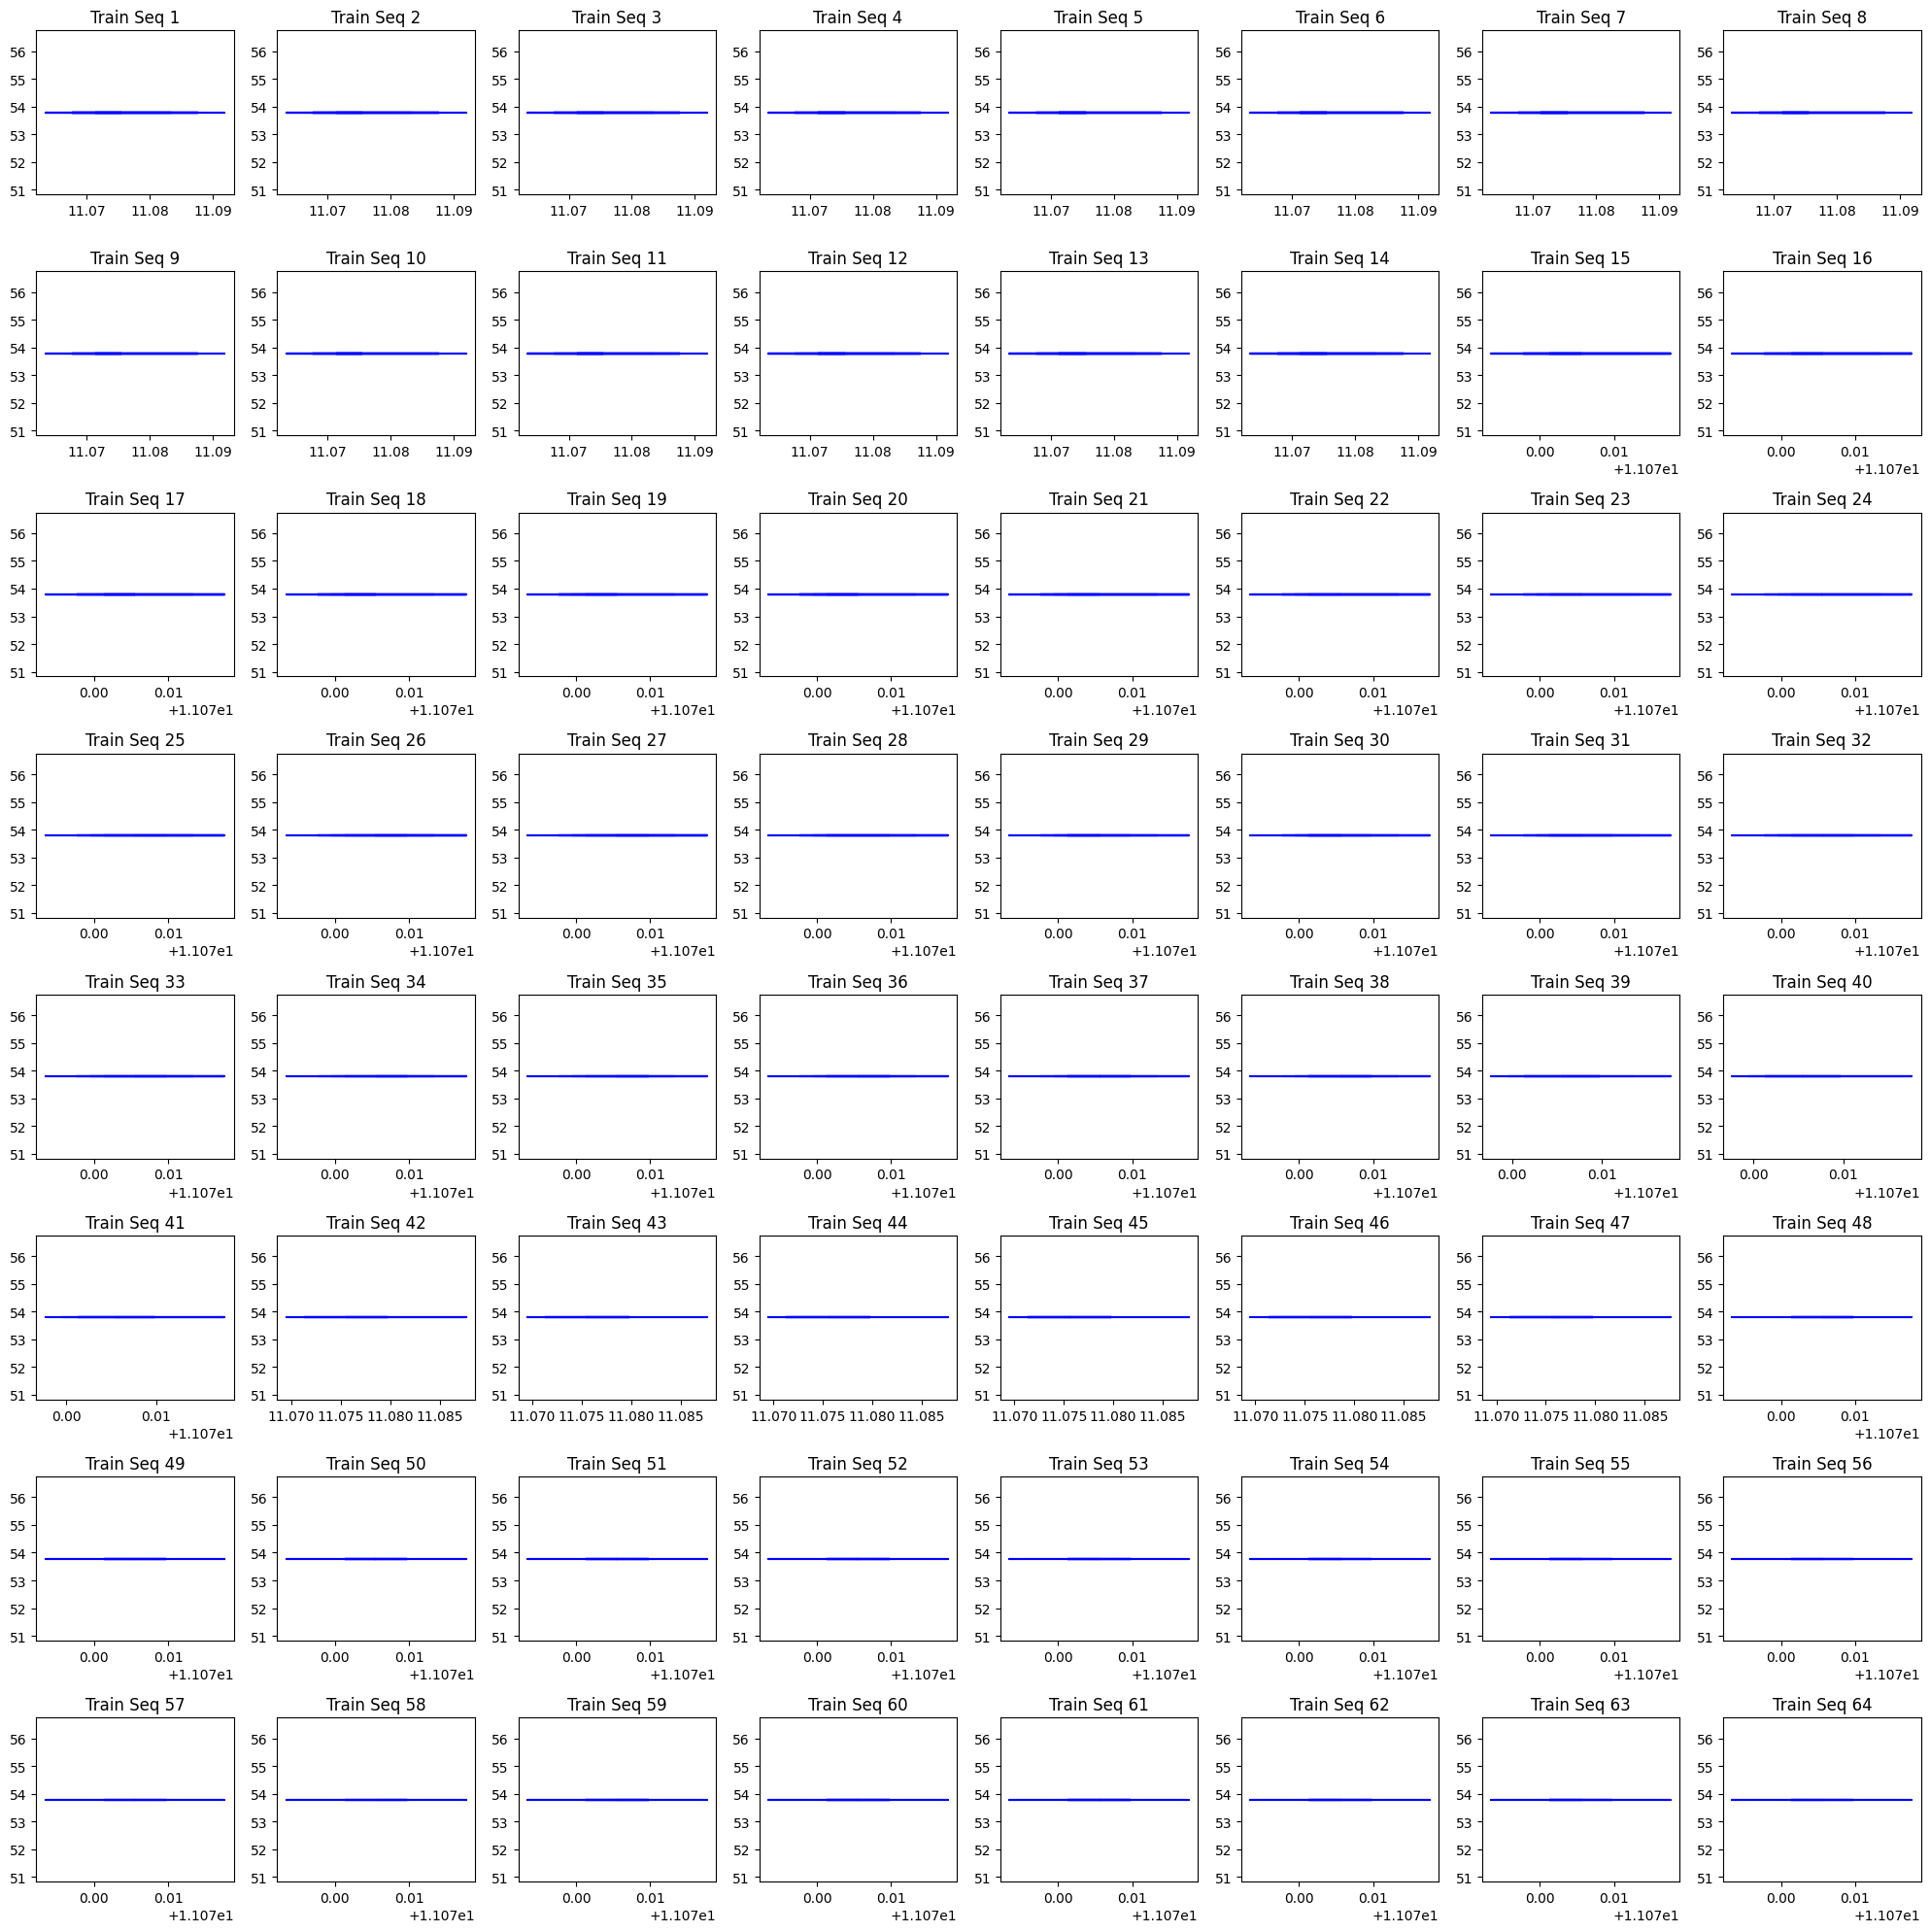

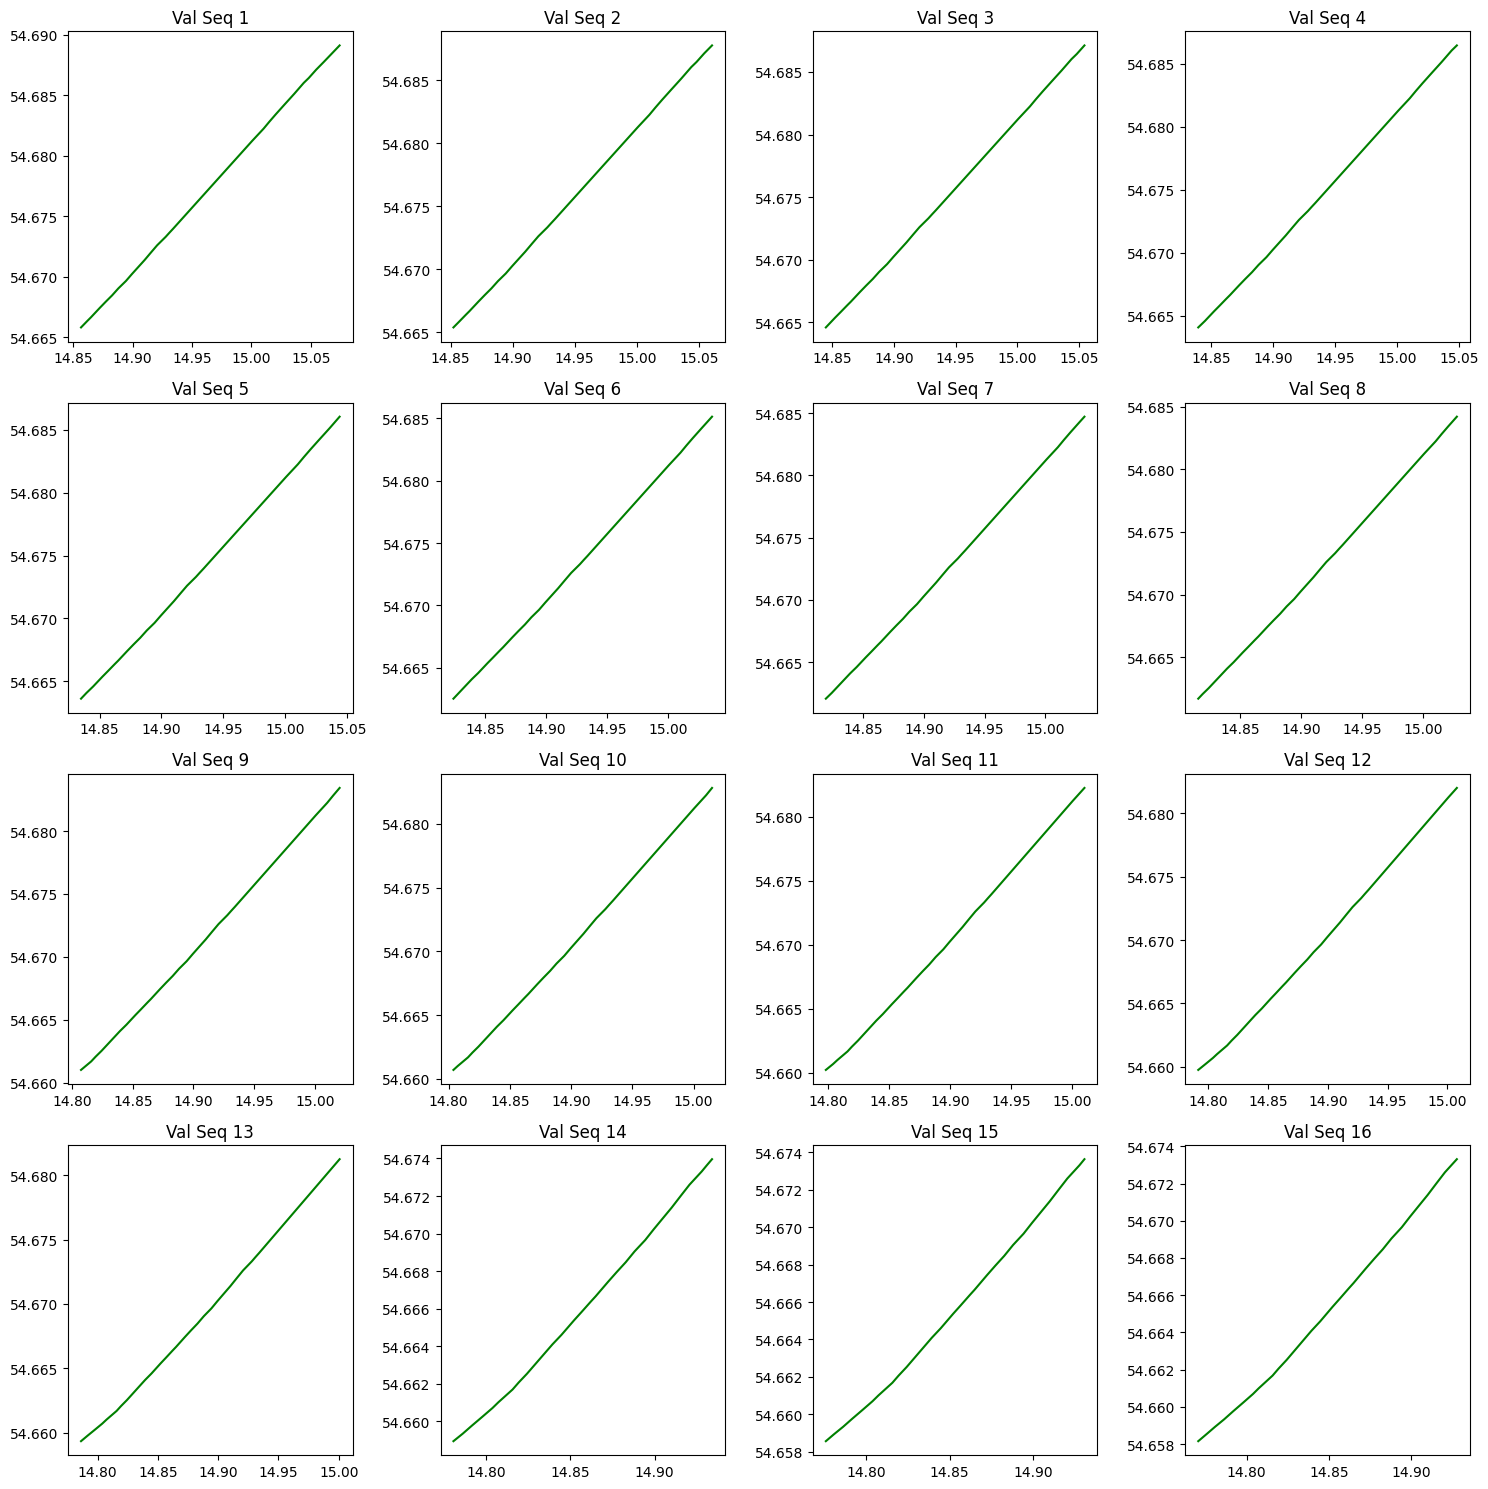

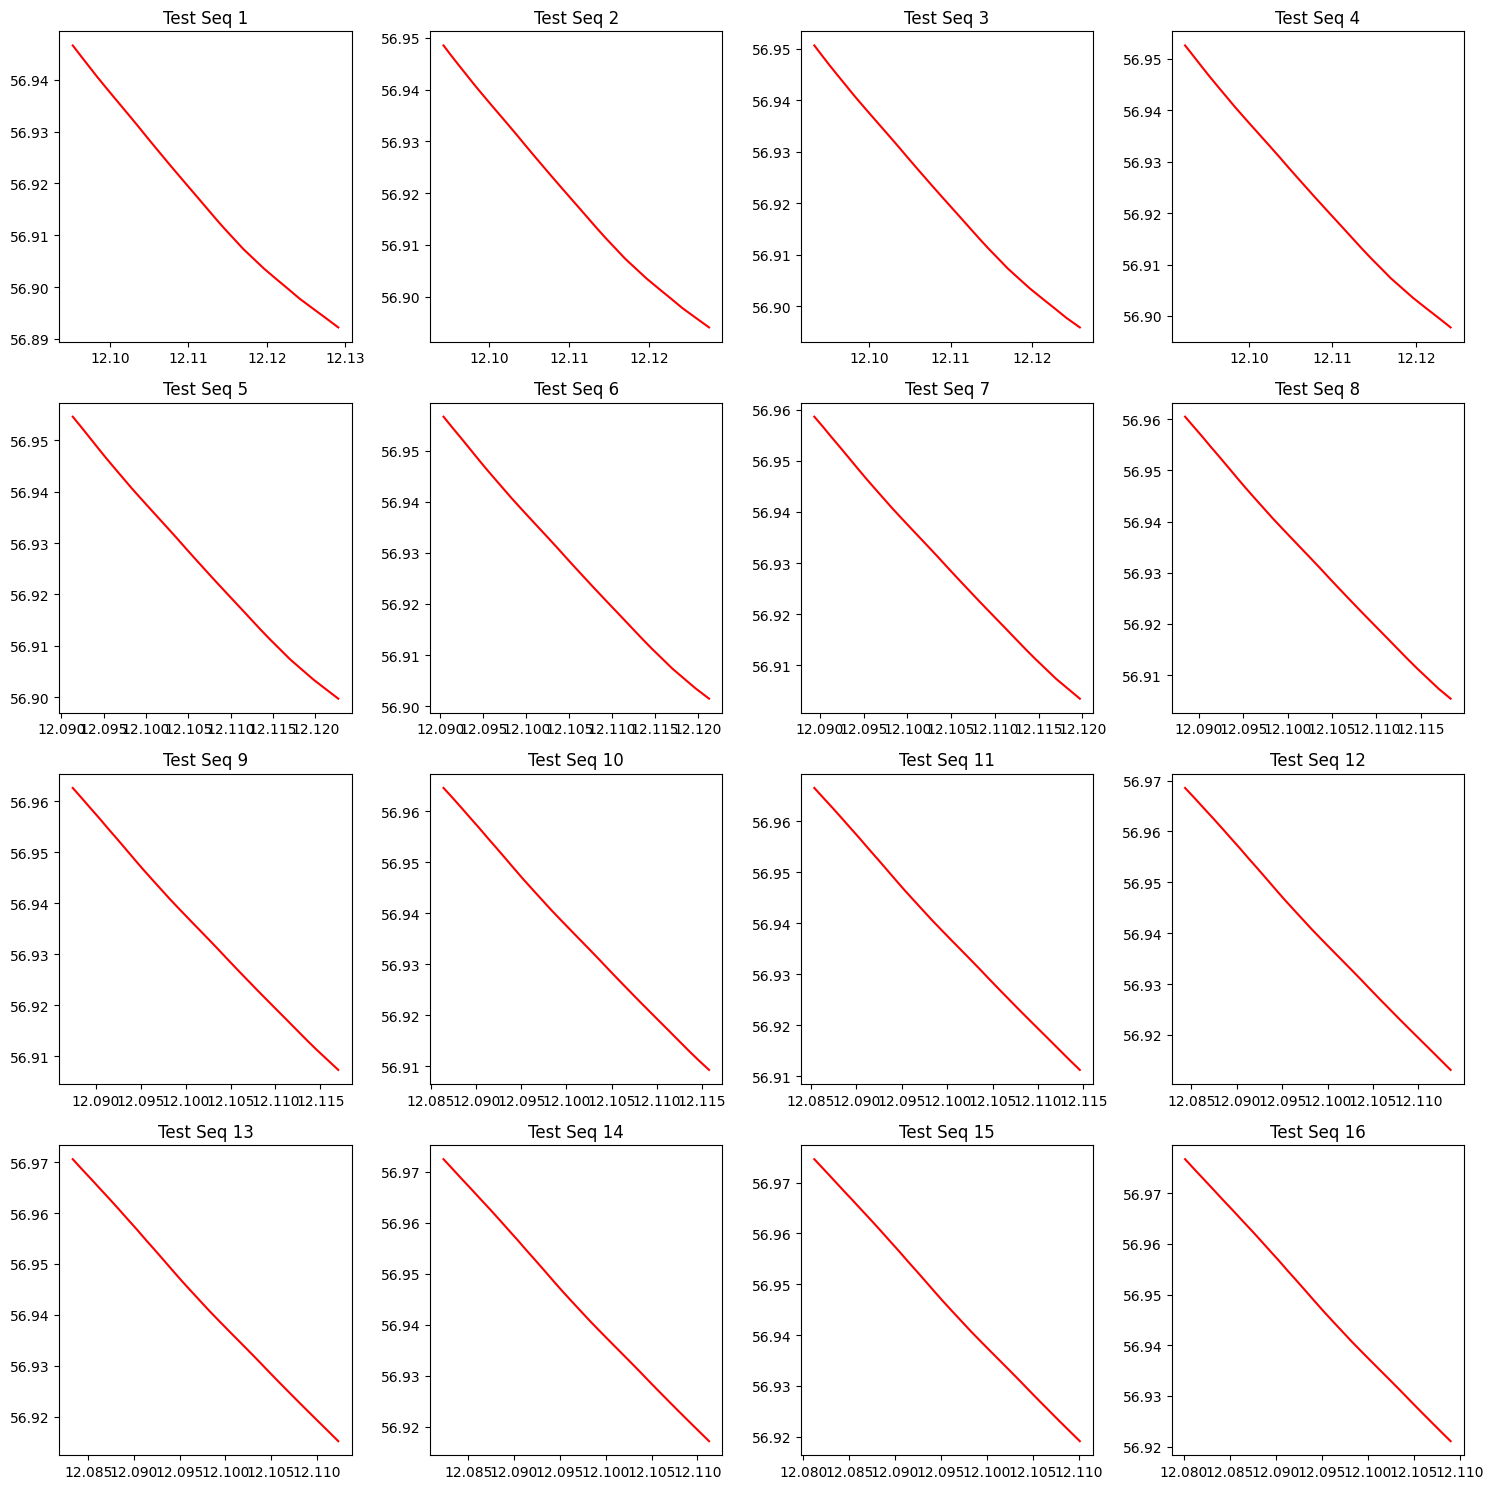

In [9]:
# plot all training, test and validation trajectories in a big figure (lots of subplots)
# training data
fig, axes = plt.subplots(8, 8, figsize=(20, 20))
for i in range(64):
    ax = axes[i // 8, i % 8]
    trajectory, target = train_dataset[i]
    trajectory = denormalize_xy(trajectory[:,3:5])
    trajectory = to_latlon(trajectory)
    ax.plot(trajectory[:,0], trajectory[:,1], "b-")
    ax.set_title(f"Train Seq {i+1}")
plt.tight_layout()
plt.show()

# validation data
fig, axes = plt.subplots(4, 4, figsize=(15, 15))
for i in range(16):
    ax = axes[i // 4, i % 4]
    trajectory, target = val_dataset[i]
    trajectory = denormalize_xy(trajectory[:, :2])
    trajectory = to_latlon(trajectory)
    ax.plot(trajectory[:,0], trajectory[:,1], "g-")
    ax.set_title(f"Val Seq {i+1}")
plt.tight_layout()
plt.show()
# test data
fig, axes = plt.subplots(4, 4, figsize=(15, 15))
for i in range(16):
    ax = axes[i // 4, i % 4]
    trajectory, target = test_dataset[i]
    trajectory = denormalize_xy(trajectory[:, :2])
    trajectory = to_latlon(trajectory)
    ax.plot(trajectory[:,0], trajectory[:,1], "r-")
    ax.set_title(f"Test Seq {i+1}")
plt.tight_layout()
plt.show()